# Reproducing the isochrons of Osinga & Moehlis (2010), step by step

This notebook computes global isochrons of the reduced Hodgkin-Huxley model by the
paper's continuation method (notebook `02_ISOCHRONS_continuation`), with XPPAUT 8.2
and its AUTO driven from Python by pyauto-xpp. The step numbers match
`isochron_recipe.pdf` and the `STEP` comments in `reproduce_isochrons.py`.

**How to use it**
1. Set what you want in the **Settings** cell (phases, number of stages, parallel workers).
2. Run all cells (*Run All*). Each step prints what it does at the XPPAUT level: the
   `.ode` file, the XPP menu action, or the AUTO settings, so you can repeat it by hand
   in XPPAUT if you like.
3. Progress bars show the phases and the stages as they are computed. Finished
   isochrons are saved one file per phase and reused on a rerun, so an interrupted run
   can simply be started again.

Needs: `pip install pyauto-xpp numpy matplotlib tqdm ipywidgets`

## Settings

| setting | meaning | the paper |
|---|---|---|
| `PHASES` | phases θ in [0, 1) to compute | `[i/100 for i in range(100)]` |
| `KMAX` | stages inside the orbit (time-k T maps) | 4 |
| `KOUT` | stages outside the orbit | 1 |
| `N_WORKERS` | isochrons computed at the same time, one XPPAUT per process | |
| `VERBOSE` | print the XPP/AUTO view of every stage (serial runs only) | |
| `OUT` | folder for the results | |

**Making it faster on your machine** (see also the last section):
* `N_WORKERS`: isochrons are independent, so they parallelise perfectly. Use about the
  number of physical CPU cores you can spare; each worker uses one core and about 100 MB.
* Fewer `PHASES` (e.g. 20 instead of 100) for a first look.
* `KMAX = 2` or `3`: stage 3 is the slowest (it can need NTST = 1200); 2 stages already
  show the first excursion.
* `KOUT = 0` if you only want the inside of the orbit.
* Results are cached per phase in `OUT`: rerunning skips finished isochrons.

In [10]:
PHASES = [0.0, 1.0]          # e.g. [i / 100 for i in range(100)] for the paper's Figure 2
KMAX = 4                     # stages inside the orbit
KOUT = 1                     # stages outside the orbit
N_WORKERS = 5                # parallel processes (1 = serial, with full printing)
VERBOSE = True               # print the XPP/AUTO view of each stage (serial runs, and the first phase)
OUT = "isochron_results"     # results folder

## Imports and the numerical constants of the paper (its Table 1)

In [11]:
import json
import multiprocessing as mp
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.path import Path as Polygon
from pyxpp.builder import ModelBuilder
from tqdm.auto import tqdm

ETA = 1e-4            # half-length eta of the linear piece L_eta(gamma) of the isochron
DS = 1e-5             # first continuation step, 0.1 eta
NTST_GAMMA = 100      # mesh intervals per period; stage k uses 100 k
AUTO_NUM = dict(ncol=4, dsmin=1e-8, dsmax=0.1, epsl=1e-8, epsu=1e-8, epss=1e-6,
                itmx=8, itnw=5, nwtn=3, iad=3, normmax=1e6, npr=100000)
NMX = 5000            # at most this many continuation points per stage
SC = np.array([100.0, 1.0])   # V and n scaled to similar sizes, for distances only
out = Path(OUT)
out.mkdir(exist_ok=True)

## Step 1. The model

The reduced Hodgkin-Huxley equations (4.1), written with pyauto-xpp's `ModelBuilder`.
The builder writes an ordinary XPP `.ode` file and loads it into XPPAUT; the file is
printed below, exactly as XPPAUT reads it.

In [12]:
FUN = [("am(v)", "0.1*(v+40)/(1-exp(-(v+40)/10))"), ("bm(v)", "4*exp(-(v+65)/18)"),
       ("an(v)", "0.01*(v+55)/(1-exp(-(v+55)/10))"), ("bn(v)", "0.125*exp(-(v+65)/80)"),
       ("minf(v)", "am(v)/(am(v)+bm(v))")]
FV = "iapp-gna*minf(v)^3*(0.8-n)*(v-ena)-gk*n^4*(v-ek)-gl*(v-el)"
FN = "an(v)*(1-n)-bn(v)*n"
PARS = dict(iapp=10, gna=120, gk=36, gl=0.3, ena=50, ek=-77, el=-54.4)
OPTS = dict(meth="rk4", bound=1e4, jac_eps=1e-7, newt_tol=1e-10)


def model_builder():
    mb = ModelBuilder("reduced_hh")
    for sig, expr in FUN:
        mb.function(sig, expr)
    return (mb.ode("v", FV).ode("n", FN).parameter(**PARS).initial(v=-60, n=0.3)
            .option(total=300, dt=0.01, maxstor=400000, **OPTS))


mb = model_builder()
print("---- reduced_hh.ode ----")
print(mb.render())
m = mb.load(out / "reduced_hh.ode")

---- reduced_hh.ode ----
am(v)=0.1*(v+40)/(1-exp(-(v+40)/10))
bm(v)=4*exp(-(v+65)/18)
an(v)=0.01*(v+55)/(1-exp(-(v+55)/10))
bn(v)=0.125*exp(-(v+65)/80)
minf(v)=am(v)/(am(v)+bm(v))
v'=iapp-gna*minf(v)^3*(0.8-n)*(v-ena)-gk*n^4*(v-ek)-gl*(v-el)
n'=an(v)*(1-n)-bn(v)*n
par iapp=10,gna=120,gk=36,gl=0.3,ena=50,ek=-77,el=-54.4
init v=-60,n=0.3
@ total=300,dt=0.01,maxstor=400000,meth=rungekutta,bound=10000.0,jac_eps=1e-07,newt_tol=1e-10
done



## Step 2. The orbit Γ, its period T and phase zero γ0

In XPPAUT: *Initialconds > Go* (integrate onto the orbit), then *Initialconds > Periodic*
with V on the y axis, which sets *total* to the period. Phase zero γ0 is the maximum of
V; it is found here by bisection on the time for the sign change of V'.

XPP: Initialconds > Go  (total=300, dt=0.01)
XPP: Initialconds > Periodic  (period from V)
T = 11.846275   (paper 11.8463)
gamma0 = (44.706382, 0.45973602)   (paper (44.7064, 0.4597))


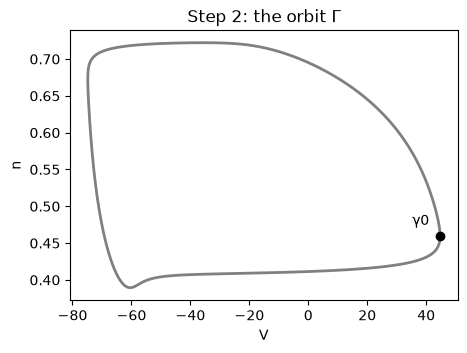

In [13]:
def flow(x, t, dt=1e-4):
    """Phi(t, x): integrate from x for time t (RK4, step at most dt)"""
    m.set(v=x[0], n=x[1])
    m.run(keep=False, total=t, dt=t / max(1, int(np.ceil(t / dt))), trans=0)
    s = m.last_state()
    return np.array([s["V"], s["N"]])


print("XPP: Initialconds > Go  (total=300, dt=0.01)")
m.run()
m.buttons.xi_vs_t("v")
print("XPP: Initialconds > Periodic  (period from V)")
m.buttons.initialconds.periodic()
T = m.numerics["total"]
g = flow(np.array([m.ics["V"], m.ics["N"]]), T - 0.05)
a, b = 0.0, 0.1
for _ in range(40):                         # bisection for V' = 0 (the maximum of V)
    c = 0.5 * (a + b)
    a, b = (c, b) if m.rhs(flow(g, c))["V"] > 0 else (a, c)
gamma0 = flow(g, 0.5 * (a + b))
m.set(v=gamma0[0], n=gamma0[1])
orb = m.run(keep=False, total=T, dt=0.001, trans=0)
poly_xy = np.c_[orb["v"], orb["n"]]
print(f"T = {T:.6f}   (paper 11.8463)")
print(f"gamma0 = ({gamma0[0]:.6f}, {gamma0[1]:.8f})   (paper (44.7064, 0.4597))")
np.savetxt(out / "orbit.dat", np.c_[orb.t, orb["v"], orb["n"]], fmt="%.10g", header="t V n")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(orb["v"], orb["n"], color="0.5", lw=2)
ax.plot(*gamma0, "o", color="k")
ax.annotate("γ0", gamma0, xytext=(-20, 8), textcoords="offset points")
ax.set(xlabel="V", ylabel="n", title="Step 2: the orbit Γ")
plt.show()

## Step 3. The direction n_s of the isochron at γ(θ)

In XPPAUT: from γ0, *Numerics > Averaging > Adj. grid* = 6400, then *New adj*. The
adjoint Z(t) is the gradient of the asymptotic phase along Γ (the infinitesimal phase
response curve). The isochron is perpendicular to it: n_s = (Z_n, −Z_V)/|Z|.

In [14]:
print("XPP: Numerics > Averaging > (grid 6400) > New adj")
A = m.buttons.numerics.averaging
A.parameters(6400)
A.new_adj()
adj = m.data


def phase_point(theta):
    """gamma(theta) and the unit tangent n_s of its isochron, pointing out of Gamma"""
    gth = gamma0.copy() if theta == 0 else flow(gamma0, theta * T)
    zv = np.interp(theta * T, adj.t, adj["v"])
    zn = np.interp(theta * T, adj.t, adj["n"])
    ns = np.array([zn, -zv]) / np.hypot(zn, zv)
    f = m.rhs(gth)
    if f["V"] * ns[1] - f["N"] * ns[0] > 0:  # Gamma turns counter-clockwise: outside is to the right of F
        ns = -ns
    return gth, ns


POINTS = {th: phase_point(th) for th in tqdm(PHASES, desc="Step 3: gamma(theta), n_s")}
for th, (gth, ns) in list(POINTS.items())[:5]:
    print(f"theta = {th:.3f}: gamma = ({gth[0]:.5f}, {gth[1]:.6f}), n_s = ({ns[0]:.8f}, {ns[1]:.8f})")

XPP: Numerics > Averaging > (grid 6400) > New adj


Step 3: gamma(theta), n_s:   0%|          | 0/2 [00:00<?, ?it/s]

theta = 0.000: gamma = (44.70638, 0.459736), n_s = (0.99999999, -0.00013711)
theta = 1.000: gamma = (44.70638, 0.459736), n_s = (0.99999999, -0.00013711)


## Step 4. The boundary value problem as an XPP `.ode` file

Orbit segments of length per = kT that end on the short piece L_η of the isochron:
`u' = per F(u)` on [0, 1], with `bndry` lines for u(1) = γ + d n_s (`v'` in a `bndry`
line means v at the right end). u(0) is free, d (= δ) is AUTO's continuation parameter.
The file is printed for the first phase, with γ and n_s filled in.

In [15]:
def bvp_builder():
    bb = ModelBuilder("isochron_bvp")
    bb.comment("orbit segments u' = per*F(u) on [0,1] that end on L_eta(gamma): u(1) = gamma + d*n_s")
    for sig, expr in FUN:
        bb.function(sig, expr)
    return (bb.ode("v", f"per*({FV})").ode("n", f"per*({FN})")
            .parameter(**PARS).parameter(per=T, gv=0, gn=0, tv=1, tn=0, d=0)
            .boundary("v'-gv-d*tv").boundary("n'-gn-d*tn")
            .option(total=1, dt=1e-4, maxstor=400000, **OPTS))


def bvp_ode_text(gth, ns):
    return bvp_builder().render().replace(
        "gv=0,gn=0,tv=1,tn=0,d=0",
        f"gv={gth[0]:.10g},gn={gth[1]:.10g},tv={ns[0]:.10g},tn={ns[1]:.10g},d=0")


gth0, ns0 = POINTS[PHASES[0]]
ode_text = bvp_ode_text(gth0, ns0)
(out / "isochron_bvp.ode").write_text(ode_text)
print(f"---- isochron_bvp.ode (theta = {PHASES[0]}) ----")
print(ode_text)


def load_bvp():
    B = bvp_builder().load(Path(tempfile.mkdtemp()) / "isochron_bvp.ode")
    B.auto.parameters("d", "per")           # AUTO's continuation parameter is d
    return B

---- isochron_bvp.ode (theta = 0.0) ----
# orbit segments u' = per*F(u) on [0,1] that end on L_eta(gamma): u(1) = gamma + d*n_s
am(v)=0.1*(v+40)/(1-exp(-(v+40)/10))
bm(v)=4*exp(-(v+65)/18)
an(v)=0.01*(v+55)/(1-exp(-(v+55)/10))
bn(v)=0.125*exp(-(v+65)/80)
minf(v)=am(v)/(am(v)+bm(v))
v'=per*(iapp-gna*minf(v)^3*(0.8-n)*(v-ena)-gk*n^4*(v-ek)-gl*(v-el))
n'=per*(an(v)*(1-n)-bn(v)*n)
par iapp=10,gna=120,gk=36,gl=0.3,ena=50,ek=-77,el=-54.4
par per=11.846275030774093,gv=44.70638155,gn=0.4597360195,tv=0.9999999906,tn=-0.0001371078909,d=0
bndry v'-gv-d*tv
bndry n'-gn-d*tn
@ total=1,dt=0.0001,maxstor=400000,meth=rungekutta,bound=10000.0,jac_eps=1e-07,newt_tol=1e-10
done



## Steps 5–8. Algorithm Isochron for one phase point

* **Step 5**: start a stage. Stage 1 starts from Γ itself (δ = 0). In XPPAUT: integrate
  the BVP file with per = T from γ, then *File > Auto > Run > Bdry Value*. XPP's AUTO
  puts the starting solution on a uniform mesh, so 6 steps with δ unbounded let the mesh
  adapt (IAD = 3) before the real continuation; if that fails, ITNW = 20, then a finer
  mesh, are tried.
* **Step 6**: choose the direction by probing 25 steps each way.
* **Step 7**: continue in δ until |δ| = η (*Par min/max* = ±η). The u(0) of every point
  is an isochron point.
* **Step 8**: start the next stage from the last segment followed by one period of Γ
  (the paper's eq. 3.5), with per = kT and NTST = 100k.

In [16]:
def xpp_view(k, ntst, itnw, gth, ns, what):
    """the stage as XPP/AUTO would see it: the changed .ode parameters and the AUTO numerics panel"""
    return (f"  [{what}] .ode: par per={k}*T={k * T:.6f}, gv={gth[0]:.6f}, gn={gth[1]:.6f}, "
            f"tv={ns[0]:.6f}, tn={ns[1]:.6f}, d=0\n"
            f"           AUTO: Run > Bdry Value, main par d; Ntst={ntst} Nmax=6 Npr={AUTO_NUM['npr']} "
            f"Ds={DS} Dsmin={AUTO_NUM['dsmin']} Dsmax=1e-6 Par min=-1 Par max=1 "
            f"EPSL={AUTO_NUM['epsl']} EPSU={AUTO_NUM['epsu']} EPSS={AUTO_NUM['epss']} ITNW={itnw} IAD={AUTO_NUM['iad']}\n"
            f"           then: Grab the last point, Run with Ds=+-{DS}, Par min=-{ETA} Par max={ETA}, Dsmax={AUTO_NUM['dsmax']}")


class Isochron:
    """Algorithm Isochron (steps 5-8) for the phase point gth with direction ns"""

    def __init__(self, B, gth, ns, verbose=False, bar=None):
        self.B, self.g, self.ns, self.verbose, self.bar = B, gth, ns, verbose, bar
        self.poly = Polygon(poly_xy)
        self.log = []
        # STEP 5a: Gamma from gamma over one period, as a solution on [0, 1]
        B.set(per=T, v=gth[0], n=gth[1], d=0)
        tr = B.run(total=1, dt=1e-4)
        self.uG = np.asarray(tr.t, float), np.c_[tr["v"], tr["n"]].astype(float)

    def say(self, text):
        if self.verbose:
            (self.bar.write if self.bar is not None else print)(text)

    @staticmethod
    def pts(points):
        return np.array([[p.u0["v"], p.u0["n"], p.par["d"]] for p in points]).reshape(-1, 3)

    def start(self, k, initial):                                     # STEP 5b
        B = self.B
        for ntst, itnw in [(NTST_GAMMA * k, 5), (NTST_GAMMA * k, 20), (2 * NTST_GAMMA * k, 20),
                           (4 * NTST_GAMMA * k, 20)]:
            self.say(xpp_view(k, ntst, itnw, self.g, self.ns, f"step 5, stage {k}"))
            B.set(per=k * T, gv=self.g[0], gn=self.g[1], tv=self.ns[0], tn=self.ns[1], d=0)
            B.auto.reset()
            first = B.auto.run("d", start="bdry value", initial=initial, ntst=ntst, ds=DS, nmax=6,
                               parmin=-1, parmax=1, **dict(AUTO_NUM, itnw=itnw, dsmax=1e-6))
            if len(first) == 6 and all(p.type != "MX" for p in first) and abs(first[-1].par["d"]) < ETA / 10:
                return first[-1], ntst, itnw
            self.log.append(f"k={k}: start with NTST={ntst}, ITNW={itnw} failed")
            self.say(f"           start failed with NTST={ntst}, ITNW={itnw}; trying the next setting")
        raise RuntimeError(f"k={k}: AUTO did not converge from the starting solution")

    def delta_back(self, sol, k):                                    # STEP 6 (helper)
        t, U = sol
        tt = (k - 1) / k
        j = int(np.clip(np.searchsorted(t, tt) - 2, 0, len(t) - 4))
        ts, Us = t[j:j + 4], U[j:j + 4]
        w = np.array([np.prod([(tt - ts[q]) / (ts[l] - ts[q]) for q in range(4) if q != l]) for l in range(4)])
        return float((w @ Us - self.g) @ self.ns)

    def score(self, u, k, direction, probe, d0):                     # STEP 6
        if k == 1:
            last = u[-max(3, len(u) // 4):, :2]
            far = last[np.hypot(*((last - self.g) / SC).T) > 1e-2]
            return 0.0 if len(far) == 0 else (self.poly.contains_points(far).mean() - 0.5) * (-direction)
        d1 = self.delta_back(probe[-1].solution, k)
        return (abs(d1) - abs(d0)) / abs(d0)

    def stage(self, k, direction, initial, nprobe=25):               # STEPS 5b-7
        B = self.B
        t0 = time.time()
        p0, ntst, itnw = self.start(k, initial)
        d0 = self.delta_back(p0.solution, k) if k > 1 else None
        scores = {}
        for n_try in (nprobe, 6 * nprobe):
            for sign in (1, -1):
                probe = B.auto.run(grab=p0.label, ds=sign * DS, nmax=n_try, parmin=-ETA, parmax=ETA, **AUTO_NUM)
                u = self.pts(probe)
                scores[sign] = self.score(u, k, direction, probe, d0)
                if scores[sign] > 0.01:
                    break
            else:
                sign = max(scores, key=scores.get)
                if scores[sign] <= 0:
                    continue
                probe = B.auto.run(grab=p0.label, ds=sign * DS, nmax=n_try, parmin=-ETA, parmax=ETA, **AUTO_NUM)
                u = self.pts(probe)
            break
        else:
            raise RuntimeError(f"k={k}: neither direction goes the requested way {scores}")
        self.say(f"  [step 6, stage {k}] direction: Ds = {sign * DS:+g} "
                 f"({'inside' if direction < 0 else 'outside'} Γ{', extends the isochron' if k > 1 else ''})")
        parts, last = [u], probe[-1]
        chunk = NMX if direction < 0 else 100
        while abs(last.par["d"]) < ETA and last.type != "MX" and sum(map(len, parts)) < NMX:
            if direction > 0 and not (-150 < last.u0["v"] < 150 and 0.15 < last.u0["n"] < 0.95):
                break
            more = B.auto.run(grab=last.label, ds=sign * DS, nmax=min(chunk, NMX - sum(map(len, parts))),
                              parmin=-ETA, parmax=ETA, **AUTO_NUM)
            if len(more) <= 1:
                break
            parts.append(self.pts(more)[1:])
            last = more[-1]
        u = np.vstack(parts)
        info = dict(k=k, side="in" if direction < 0 else "out", ntst=ntst, itnw_start=itnw,
                    points=len(u), d_end=float(last.par["d"]), seconds=round(time.time() - t0, 1))
        self.log.append(json.dumps(info))
        self.say(f"  [step 7, stage {k}] {info['points']} isochron points, delta at the end "
                 f"{info['d_end']:.2e} (eta = {ETA}), {info['seconds']} s")
        return u, last.solution, info

    def concatenate(self, k, sol):                                   # STEP 8 (eq. 3.5)
        (ts, Us), (tG, UG) = sol, self.uG
        tt = np.linspace(0, 1, 4000 * k + 1)
        a = tt <= (k - 1) / k
        U = np.empty((len(tt), 2))
        for j in range(2):
            U[a, j] = np.interp(tt[a] * k / (k - 1), ts, Us[:, j])
            U[~a, j] = np.interp(tt[~a] * k - (k - 1), tG, UG[:, j])
        self.say(f"  [step 8] stage {k} starts from: last segment of stage {k - 1} ({k - 1} periods) "
                 f"+ one period of Γ, rescaled to [0, 1]; jump of size eta at s = {(k - 1) / k:.3f}")
        return tt, U

    def run(self, kmax=4, kout=1):
        res = {}
        for direction, kk in ((-1, kmax), (+1, kout)):
            init = self.uG                                           # STEP 5a
            for k in range(1, kk + 1):
                u, sol, info = self.stage(k, direction, init)
                res[("in" if direction < 0 else "out", k)] = (u, info)
                if self.bar is not None:
                    self.bar.set_postfix(stage=f"{info['side']} k={k}", points=info["points"])
                    self.bar.update(1)
                if k < kk:
                    init = self.concatenate(k + 1, sol)               # STEP 8
        return res

## Step 9. All phases: compute, save, plot

One file per phase, `isochron_<θ>.dat` (columns V n δ stage side; side −1 inside Γ, +1
outside). Phases whose file already exists are skipped, so an interrupted run resumes.
With `N_WORKERS > 1` the phases run in parallel, each worker with its own XPPAUT.

In [17]:
def iso_file(theta):
    return out / f"isochron_{theta:.3f}.dat"


def save(theta, res, log):
    rows = [np.c_[u, np.full(len(u), k), np.full(len(u), -1 if side == "in" else 1)]
            for (side, k), (u, info) in res.items()]
    np.savetxt(iso_file(theta), np.vstack(rows), fmt="%.12g", header="V n delta stage side")
    (out / f"isochron_{theta:.3f}.log").write_text("\n".join(log) + "\n")


_B = None


def _worker(job):
    """one phase in a worker process (its own XPPAUT copy, loaded once per process)"""
    global _B
    theta, gth, ns = job
    if _B is None:
        _B = load_bvp()
    t0 = time.time()
    iso = Isochron(_B, gth, ns)
    res = iso.run(KMAX, KOUT)
    save(theta, res, iso.log)
    return theta, round(time.time() - t0, 1), sum(len(u) for u, _ in res.values())


todo = [th for th in PHASES if not iso_file(th).exists()]
print(f"{len(PHASES) - len(todo)} of {len(PHASES)} phases already computed; {len(todo)} to do")
t_all = time.time()
serial = todo if N_WORKERS <= 1 else todo[:1]      # the first phase always runs here, printed stage by stage
parallel = [th for th in todo if th not in serial]
if serial:
    B = load_bvp()
    for i, th in enumerate(tqdm(serial, desc="phases (here)")):
        gth, ns = POINTS[th]
        with tqdm(total=KMAX + KOUT, desc=f"θ = {th:.3f}", leave=True) as bar:
            iso = Isochron(B, gth, ns, verbose=VERBOSE and (i == 0 or N_WORKERS <= 1), bar=bar)
            res = iso.run(KMAX, KOUT)
        save(th, res, iso.log)
if parallel:
    # the other phases in N_WORKERS processes, a summary line per phase
    ctx = mp.get_context("fork")
    with ctx.Pool(min(N_WORKERS, len(parallel))) as pool, tqdm(total=len(parallel), desc="phases (workers)") as bar:
        for th, sec, npts in pool.imap_unordered(_worker, [(th, *POINTS[th]) for th in parallel]):
            bar.set_postfix(last=f"θ={th:.3f}: {npts} pts, {sec} s")
            bar.update(1)
print(f"done in {time.time() - t_all:.0f} s; results in {out}/")

1 of 2 phases already computed; 1 to do


phases (here):   0%|          | 0/1 [00:00<?, ?it/s]

θ = 1.000:   0%|          | 0/5 [00:00<?, ?it/s]

  [step 5, stage 1] .ode: par per=1*T=11.846275, gv=44.706382, gn=0.459736, tv=1.000000, tn=-0.000137, d=0
           AUTO: Run > Bdry Value, main par d; Ntst=100 Nmax=6 Npr=100000 Ds=1e-05 Dsmin=1e-08 Dsmax=1e-6 Par min=-1 Par max=1 EPSL=1e-08 EPSU=1e-08 EPSS=1e-06 ITNW=5 IAD=3
           then: Grab the last point, Run with Ds=+-1e-05, Par min=-0.0001 Par max=0.0001, Dsmax=0.1
  [step 6, stage 1] direction: Ds = +1e-05 (inside Γ)
  [step 7, stage 1] 719 isochron points, delta at the end -1.03e-04 (eta = 0.0001), 7.9 s
  [step 8] stage 2 starts from: last segment of stage 1 (1 periods) + one period of Γ, rescaled to [0, 1]; jump of size eta at s = 0.500
  [step 5, stage 2] .ode: par per=2*T=23.692550, gv=44.706382, gn=0.459736, tv=1.000000, tn=-0.000137, d=0
           AUTO: Run > Bdry Value, main par d; Ntst=200 Nmax=6 Npr=100000 Ds=1e-05 Dsmin=1e-08 Dsmax=1e-6 Par min=-1 Par max=1 EPSL=1e-08 EPSU=1e-08 EPSS=1e-06 ITNW=5 IAD=3
           then: Grab the last point, Run with Ds=+-1e-05,

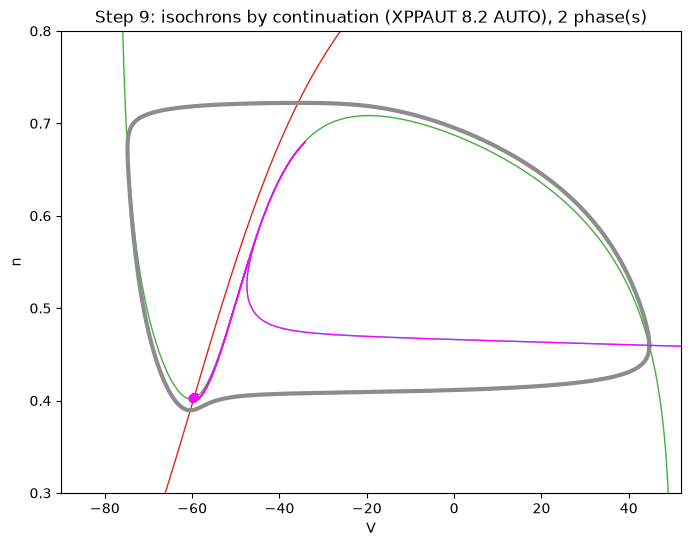

In [18]:
V, N = np.meshgrid(np.linspace(-90, 52, 600), np.linspace(0.3, 0.8, 400))
with np.errstate(all="ignore"):
    am = 0.1 * (V + 40) / (1 - np.exp(-(V + 40) / 10)); bm = 4 * np.exp(-(V + 65) / 18)
    an = 0.01 * (V + 55) / (1 - np.exp(-(V + 55) / 10)); bn = 0.125 * np.exp(-(V + 65) / 80)
vdot = 10 - 120 * (am / (am + bm)) ** 3 * (0.8 - N) * (V - 50) - 36 * N ** 4 * (V + 77) - 0.3 * (V + 54.4)
ndot = an * (1 - N) - bn * N
fig, ax = plt.subplots(figsize=(8, 6))
ax.contour(V, N, vdot, [0], colors="#41b13a", linewidths=1)
ax.contour(V, N, ndot, [0], colors="#e3241b", linewidths=1)
ax.plot(orb["v"], orb["n"], color="0.55", lw=3)
cmap = plt.get_cmap("cool")
for th in PHASES:
    d = np.loadtxt(iso_file(th))
    for side in (-1, 1):
        for k in range(1, KMAX + 1):
            s = d[(d[:, 4] == side) & (d[:, 3] == k)]
            if len(s):
                ax.plot(s[:, 0], s[:, 1], color=cmap(th), lw=1)
ax.set(xlim=(-90, 52), ylim=(0.3, 0.8), xlabel="V", ylabel="n",
       title=f"Step 9: isochrons by continuation (XPPAUT 8.2 AUTO), {len(PHASES)} phase(s)")
fig.savefig(out / "isochrons.png", dpi=130)
plt.show()

## Making it faster on your machine

Rough costs on one core: the setup (steps 1–4) takes a few seconds; one isochron with
4 stages inside and 1 outside takes 2–6 minutes (θ = 0 about 5 minutes, θ = 0.3 about
2.5 minutes); all 100 isochrons take about 4.5 hours of computing.

| what | how | effect | cost |
|---|---|---|---|
| run phases in parallel | `N_WORKERS` = cores you can spare | time ÷ N_WORKERS (phases are independent) | one core and ~100 MB per worker |
| fewer phases | `PHASES = [i/20 for i in range(20)]` | 5× faster than 100 | coarser picture |
| fewer stages | `KMAX = 2` or `3` | stage 3 is the most expensive (up to NTST = 1200) | isochrons stop earlier inside Γ |
| no outside branches | `KOUT = 0` | small saving (outside stages take ~2 s) | no branches outside Γ |
| resume | rerun the notebook | finished phases are skipped | none |
| headless long runs | run `reproduce_isochrons.py` with `nohup` | survives closing Jupyter | no progress bars |

Settings to leave alone unless you check the result: the tolerances (EPSL, EPSU), η and
NTST control the accuracy of the isochrons; loosening them is faster but changes the
points. Threads do not help a single isochron: AUTO's continuation is sequential.